In [47]:
import numpy as np  #for calculating accuray of prediction
import pandas as pd  #for reading data and understanding schema of data
import matplotlib.pyplot as plt  #for visualization
%matplotlib inline 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
import joblib


In [5]:
df=pd.read_csv('data/usa_housing.csv')
df.count()

AvgAreaIncome              5000
AvgAreaHouseAge            5000
AvgAreaNumberOfRooms       5000
AvgAreaNumberOfBedrooms    5000
AreaPopulation             5000
Price                      5000
Address                    5000
dtype: int64

In [7]:
df.columns

Index(['AvgAreaIncome', 'AvgAreaHouseAge', 'AvgAreaNumberOfRooms',
       'AvgAreaNumberOfBedrooms', 'AreaPopulation', 'Price', 'Address'],
      dtype='object')

In [8]:
### our ml model given features predict the price of house
'''['AvgAreaIncome', 'AvgAreaHouseAge', 'AvgAreaNumberOfRooms',
       'AvgAreaNumberOfBedrooms', 'AreaPopulation'] 
target /lable : 'Price'
'Address' is outlier ,address is string it may not help in estalishing model
 '''      
df.info() #schema interpretation of dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   AvgAreaIncome            5000 non-null   float64
 1   AvgAreaHouseAge          5000 non-null   float64
 2   AvgAreaNumberOfRooms     5000 non-null   float64
 3   AvgAreaNumberOfBedrooms  5000 non-null   int64  
 4   AreaPopulation           5000 non-null   float64
 5   Price                    5000 non-null   float64
 6   Address                  5000 non-null   object 
dtypes: float64(5), int64(1), object(1)
memory usage: 273.6+ KB


In [49]:
df

,AvgAreaIncome,AvgAreaHouseAge,AvgAreaNumberOfRooms,AvgAreaNumberOfBedrooms,AreaPopulation,Price,Address
0,62473.77,6.11,4.6,5,72812.0,479938.62,"822 Main St, City 1, USA"
1,64345.52,10.06,4.9,4,99025.0,521031.77,"622 Main St, City 2, USA"
2,65905.25,3.73,3.1,4,46244.0,459860.98,"630 Main St, City 3, USA"
3,65147.48,2.01,3.6,2,93728.0,258837.26,"772 Main St, City 4, USA"
4,53181.94,12.96,3.2,3,55266.0,450037.02,"520 Main St, City 5, USA"
...,...,...,...,...,...,...,...
4995,75475.93,6.41,7.0,4,43247.0,534669.01,"389 Main St, City 4996, USA"
4996,79313.30,10.07,6.7,4,90882.0,278046.71,"655 Main St, City 4997, USA"
4997,62063.20,5.13,6.2,5,99940.0,344357.29,"669 Main St, City 4998, USA"
4998,73552.50,5.85,4.2,4,56495.0,430817.11,"172 Main St, City 4999, USA"


In [10]:
### get the statistics of columns
df.describe()

,AvgAreaIncome,AvgAreaHouseAge,AvgAreaNumberOfRooms,AvgAreaNumberOfBedrooms,AreaPopulation,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,65196.708526,8.493784,5.483920,3.497800,60019.733400,397871.639786
std,15061.120152,3.716778,1.455509,1.107177,23270.228739,100531.467867
min,6760.330000,2.000000,3.000000,2.000000,20003.000000,61837.560000
25%,55193.345000,5.267500,4.200000,3.000000,39880.750000,331489.067500
50%,65201.745000,8.520000,5.500000,4.000000,60351.500000,397629.840000
75%,75338.690000,11.730000,6.800000,4.000000,79996.000000,465675.655000
max,115388.480000,15.000000,8.000000,5.000000,99997.000000,750890.620000


In [11]:
### output of describe can be transpose usin T  which shuffles csv and first column heading
df.describe().T


,count,mean,std,min,25%,50%,75%,max
AvgAreaIncome,5000.0,65196.708526,15061.120152,6760.33,55193.3450,65201.745,75338.690,115388.48
AvgAreaHouseAge,5000.0,8.493784,3.716778,2.00,5.2675,8.520,11.730,15.00
AvgAreaNumberOfRooms,5000.0,5.483920,1.455509,3.00,4.2000,5.500,6.800,8.00
AvgAreaNumberOfBedrooms,5000.0,3.497800,1.107177,2.00,3.0000,4.000,4.000,5.00
AreaPopulation,5000.0,60019.733400,23270.228739,20003.00,39880.7500,60351.500,79996.000,99997.00
Price,5000.0,397871.639786,100531.467867,61837.56,331489.0675,397629.840,465675.655,750890.62


In [14]:
# Separate feature and target
x=df[['AvgAreaIncome', 'AvgAreaHouseAge', 'AvgAreaNumberOfRooms',
       'AvgAreaNumberOfBedrooms', 'AreaPopulation' ]]
y=df['Price']

In [15]:
x

,AvgAreaIncome,AvgAreaHouseAge,AvgAreaNumberOfRooms,AvgAreaNumberOfBedrooms,AreaPopulation
0,62473.77,6.11,4.6,5,72812.0
1,64345.52,10.06,4.9,4,99025.0
2,65905.25,3.73,3.1,4,46244.0
3,65147.48,2.01,3.6,2,93728.0
4,53181.94,12.96,3.2,3,55266.0
...,...,...,...,...,...
4995,75475.93,6.41,7.0,4,43247.0
4996,79313.30,10.07,6.7,4,90882.0
4997,62063.20,5.13,6.2,5,99940.0
4998,73552.50,5.85,4.2,4,56495.0


In [16]:
y

0       479938.62
1       521031.77
2       459860.98
3       258837.26
4       450037.02
          ...    
4995    534669.01
4996    278046.71
4997    344357.29
4998    430817.11
4999    318630.46
Name: Price, Length: 5000, dtype: float64

In [30]:
#split the data in train and test
x_train,x_test,y_train,y_test =train_test_split(x,y,test_size=0.4,random_state=42)

In [19]:
x_train

,AvgAreaIncome,AvgAreaHouseAge,AvgAreaNumberOfRooms,AvgAreaNumberOfBedrooms,AreaPopulation
4576,66471.51,4.47,6.1,3,31587.0
1088,74099.59,2.18,6.8,5,69262.0
479,61562.31,11.28,6.1,2,91655.0
727,53965.90,7.09,3.5,2,35929.0
3783,80218.33,2.44,7.8,3,51973.0
...,...,...,...,...,...
4426,77307.60,12.20,3.5,5,20391.0
466,94277.17,12.39,3.7,4,84629.0
3092,71699.63,3.66,5.1,3,77397.0
3772,70466.72,3.63,6.8,4,48648.0


In [20]:
y_train

4576    349943.41
1088    358577.13
479     673832.68
727     490985.25
3783    432735.37
          ...    
4426    421934.04
466     245678.05
3092    300450.98
3772    310646.75
860     538842.10
Name: Price, Length: 3000, dtype: float64

In [21]:
linear_regressoin= LinearRegression()
linear_regressoin.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [22]:
linear_regressoin

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
linear_regressoin.intercept_

np.float64(413473.6581318659)

In [32]:
housepredictions=linear_regressoin.predict(x_test)
housepredictions

array([393265.33739656, 397806.06607128, 397872.06638787, ...,
       396966.41002361, 390056.63298172, 394300.73561219], shape=(2000,))

In [34]:
y_test

1501    449598.62
2586    599879.68
2653    411994.91
1055    184026.59
705     353384.64
          ...    
331     421264.44
3100    511128.71
1454    143494.90
342     199655.12
3209    238860.71
Name: Price, Length: 2000, dtype: float64

In [39]:
accuracy =np.average(housepredictions == y_test )
accuracy

np.float64(0.0)

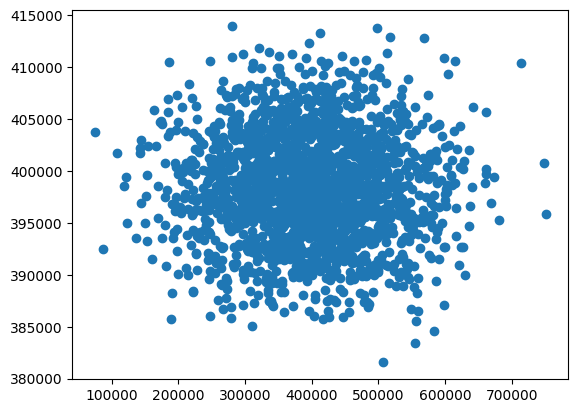

In [35]:
#scatter plotting
fig =plt.figure()
plt.scatter(y_test,housepredictions)

In [45]:
cols = ["AvgAreaIncome", "AvgAreaHouseAge", "AvgAreaNumberOfRooms", 
        "AvgAreaNumberOfBedrooms", "AreaPopulation"]

new_data = pd.DataFrame([[55193.345000,5.267500,4.200000,3.000000,39880.750000]], columns=cols)

prediction = linear_regressoin.predict(new_data)
print(prediction)

# x_new =[[55193.345000,5.267500,4.200000,3.000000,39880.750000]]
# predictval =linear_regressoin.predict(x_new)
# predictval


[403814.7201423]


In [48]:
joblib.dump(linear_regressoin,'usahousing_model.pkl')


['usahousing_model.pkl']